In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import scipy.sparse as sps
from scipy.fft import dct, idct
import jlinops




# from solvers import GKSIAS
# from psolvers import PGKSIAS
# from rsolvers import RIASGKS

from msolver import IASGKS, MMGKS, VanillaGKS

# Setup toy problem

In [2]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

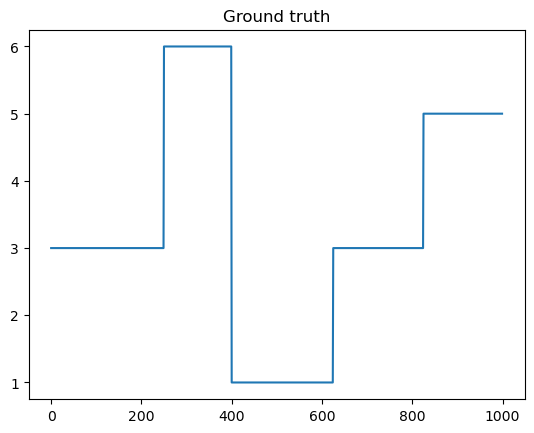

In [3]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.show()

In [4]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [5]:
F = DCT1D(n)
F_explicit = jlinops.black_box_to_dense(F)

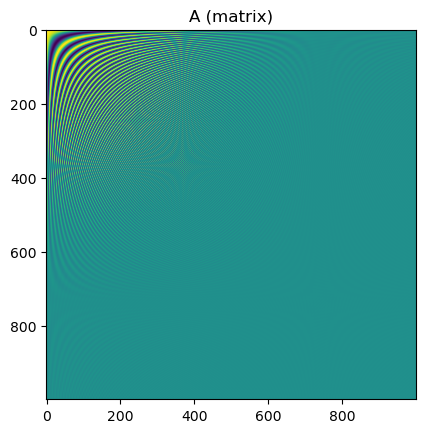

In [6]:
plt.imshow(F_explicit)
plt.title("A (matrix)")
plt.show()

In [7]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[25:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

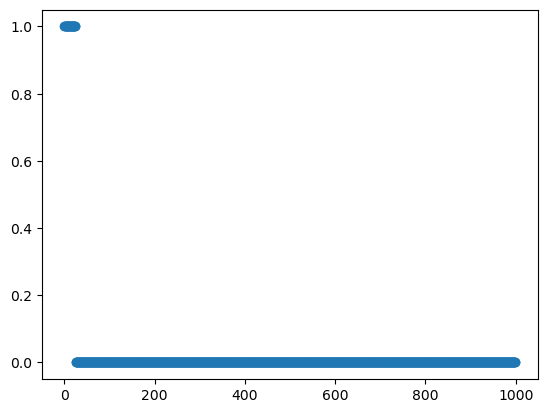

In [8]:
plt.scatter(grid, mask)
plt.show()

In [29]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_sigma = 0.01*np.amax(b_true)
noise_var = noise_sigma**2
b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

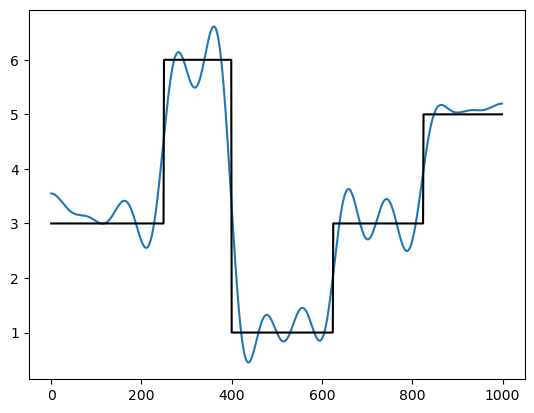

In [30]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Run PGKS (MM)

In [31]:
q = 1.0
epsilon = 1e-3
weight_params = {
    "q": q,
    "epsilon": epsilon,
}

In [32]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

In [33]:
# Set method
method = "dp"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)


err_norm_sq = len(b) # in expectation

# Build solver
mmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

In [34]:
data = mmgks_solver.solve(n_iter=30, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = mmgks_solver.solve_with_priorconditioning(n_iter=35, init_dim=5, x0=None, lambdah0=1e0, lambdah_min=1e-7, lambdah_max=1e7,
                                                 regparam=method, x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

0.5234241197419562
0.6121063807117533
0.625646789175521
0.6322573401747081
0.6445079884282762
0.6508849554330327
0.6604519272332221
0.6687431464772888
0.6762462376809328
0.684961974521782
0.6941907240161349
0.7005360867751591
0.7078210796963834
0.7146338916943749
0.720489729132036
0.7283285206649818
0.7353745587673605
0.7433031124763322
0.7477167049379321
0.7559577425585594
0.7618093416170926
0.7706035397080044
0.7774623187511254
0.784231319824818
0.7899590749017565
0.7962639167149173
0.7993949431597624
0.8054548221290329
0.8105312765151441
0.8157720350509465


0.35966178035195856
0.1313155781551691
0.09223581806511036
0.059455209714226236
0.06495822254786308
0.06646414739727093
0.07229877106395467
0.07516348824034524
0.08475577081839436
0.08831746828141551
0.09090261167577746
0.08896680856590959
0.09323847237929006
0.0957181169661012
0.0923279789397209
0.0955046319869375
0.09383889308891726
0.0922471902928819
0.09235455668071618
0.09191288104139471
0.09199459241886596
0.09199373449403328
0.0919937138149078
0.09199371291098624
0.09199371287801714
0.09199371288419957
0.09199371288435974
0.0919937128844717
0.09199371288447873
0.09199371288447705
0.09199371288447437
0.09199371288448403
0.09199371288448008
0.09199371288447263
0.09199371288447687


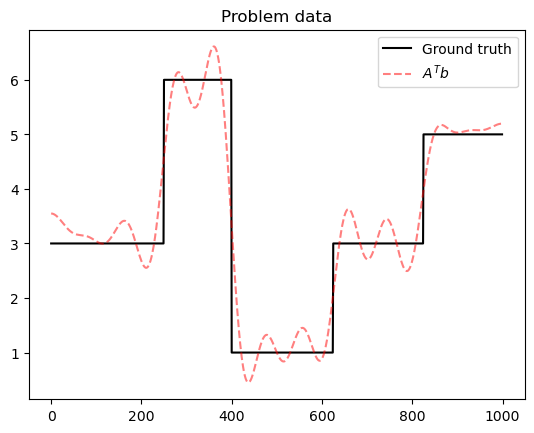

In [35]:
plt.plot(ground_truth, color="k", label="Ground truth")
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Problem data")
plt.legend()
plt.show()

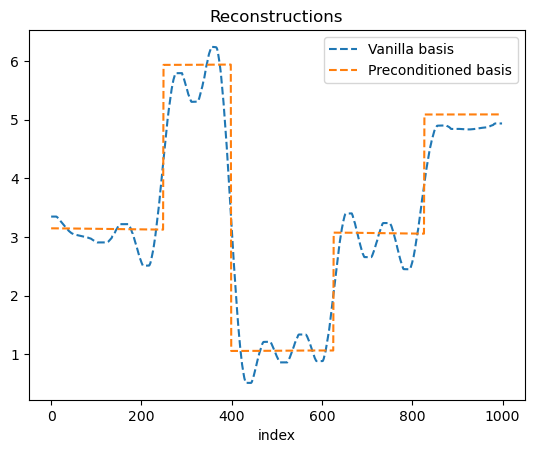

In [36]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
# plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

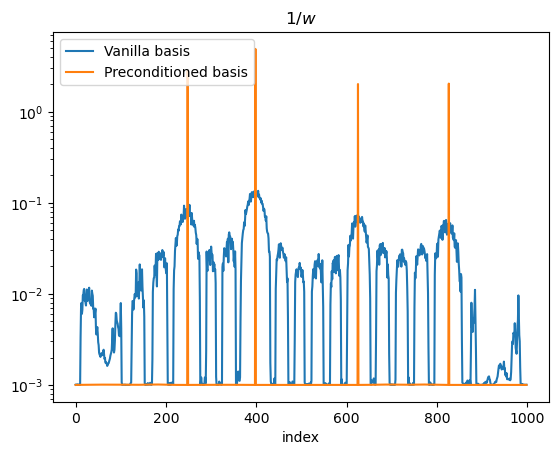

In [37]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

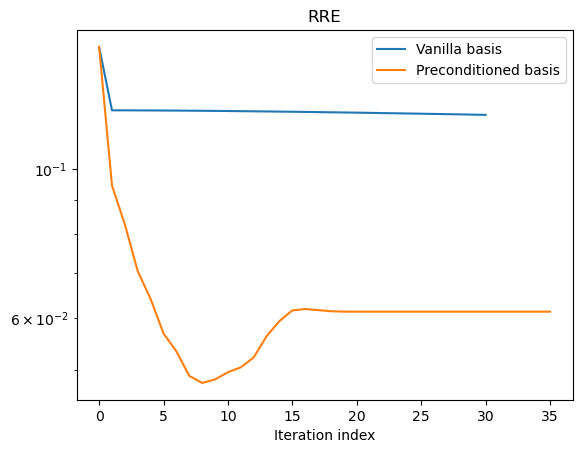

In [38]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

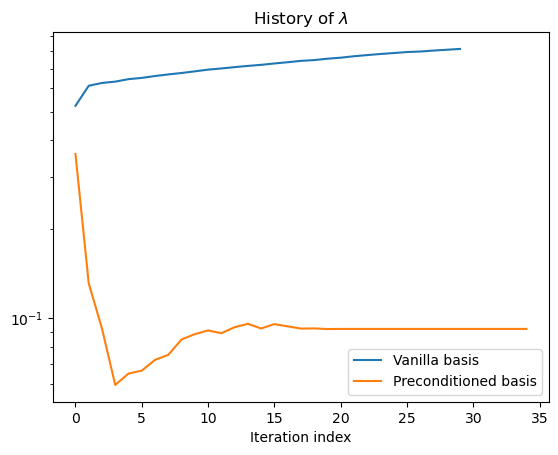

In [39]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

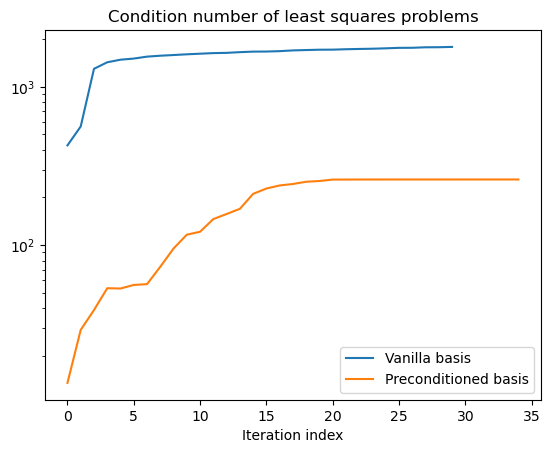

In [40]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# Run PGKS (IAS)

In [50]:
n_iters = 200

# weight_params = {
#     "hyperpr_r": 1.0,
#     "hyperpr_beta": 1.5 + 1e-9,
# }

weight_params = {
    "hyperpr_r": -1.0,
    "hyperpr_beta": 1.0,
}

In [51]:
# Set method
method = "dp3"

# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)

err_norm_sq = len(b) # in expectation

# Build solver
iasgks_solver = IASGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)


# # Run the solver
# ias_data = ias_solver.solve(n_iter=n_iters, init_dim=5, hyperpr_r=hyperpr_r, hyperpr_beta=hyperpr_beta, x_true=ground_truth, regparam=method, regparam_fixed=1e0)


In [60]:
data = iasgks_solver.solve(n_iter=60, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

pdata = iasgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                                 regparam="dp", x_true=ground_truth, weight_params=weight_params,
                                                 regparam_kwargs={"eta":1.01})

181.35863416379647
238.17001826575205
297.44539169630974
319.8527295620565
286.86409451915074
167.9848736754269
98.19872343581171
77.53893751742206
69.43868765296308
65.73802182907957
63.63477445168017
62.16839745776087
61.24511360737193
60.551218214279956
60.000893195101234
59.56066163925986
59.20959001958904
58.9359877351567
58.71891739982333
58.51790583282869
58.336091296681424
58.16303783090561
57.97694570566485
57.79575088778645
57.610466786872074
57.437521123520526
57.290239797928194
57.171704685487875
57.08018846761589
56.99497342131969
56.92311921961992
56.859773317350005
56.79707598665938
56.73761611720552
56.68326493179907
56.638695046089786
56.602368861013666
56.57182369299977
56.54742966702878
56.52757724994552
56.51017984264618
56.49495324813207
56.48070179006456
56.465853629496756
56.452897331266854
56.442076101838495
56.43259599594699
56.42324016911323
56.414602423442524
56.40727847343826
56.40099809101768
56.395477875062625
56.39069190085081
56.385938513547956
56.381997

1e-06


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/msolver.py:505: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-06
1e-06
35.46996233772145
50.02698957428964
57.73927112542076
61.62178890808102
65.64307461352438
77.13636085996923
80.15011938679
88.47287891908394
91.78427265541247
92.35138628687626
92.41297411105603
92.42195004798957
92.43104043157558
92.4315206798125
92.43191781678364
92.43205539523682
92.43212033544233
92.4321101608002
92.43210799107325
92.43210755035018
92.43210744471628
92.4321073958643
92.43210737024452
92.43210736192688
92.43210736448702
92.43210736569927
92.43210736585779
92.43210736589174
92.43210736589994
92.43210736590243
92.43210736590268
92.4321073659029
92.43210736590284
92.43210736590295
92.43210736590297
92.43210736590267
92.43210736590277
92.4321073659029
92.43210736590282
92.43210736590275
92.4321073659029
92.4321073659029
92.43210736590297
92.43210736590291
92.43210736590291
92.43210736590288
92.43210736590288
92.4321073659029
92.43210736590292
92.43210736590304
92.43210736590291
92.43210736590292
92.43210736590294
92.4321073659028
92.43210736590301
92.4321073

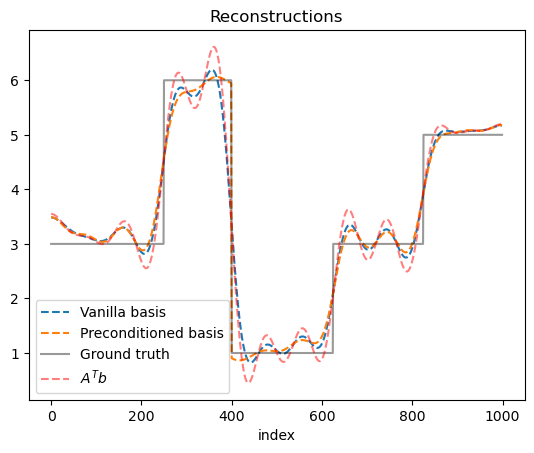

In [61]:
plt.plot(data['x'], label="Vanilla basis", ls="--")
plt.plot(pdata['x'], label="Preconditioned basis", ls="--")
plt.plot(ground_truth, label="Ground truth", color="k", alpha=0.4)
plt.plot(A.T @ b, color="red", ls="--", alpha=0.5, label="$A^T b$")
plt.title("Reconstructions")
plt.xlabel("index")
plt.legend()
plt.show()

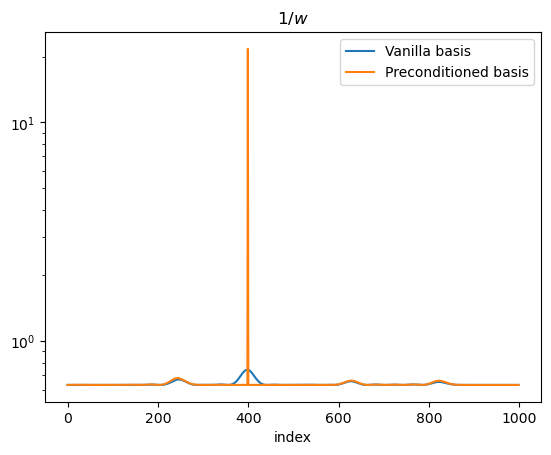

In [54]:
plt.semilogy(1.0/data['w'], label="Vanilla basis")
plt.semilogy(1.0/pdata['w'], label="Preconditioned basis")
plt.title("$1/w$")
plt.xlabel("index")
plt.legend()
plt.show()

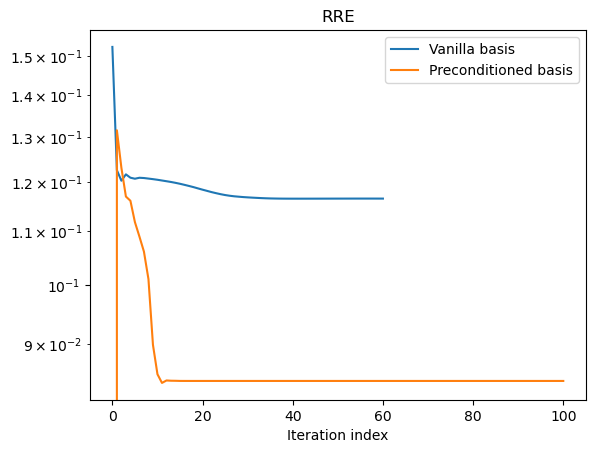

In [55]:
plt.semilogy(data["rre_history"], label="Vanilla basis")
plt.semilogy(pdata["rre_history"], label="Preconditioned basis")
plt.title("RRE")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

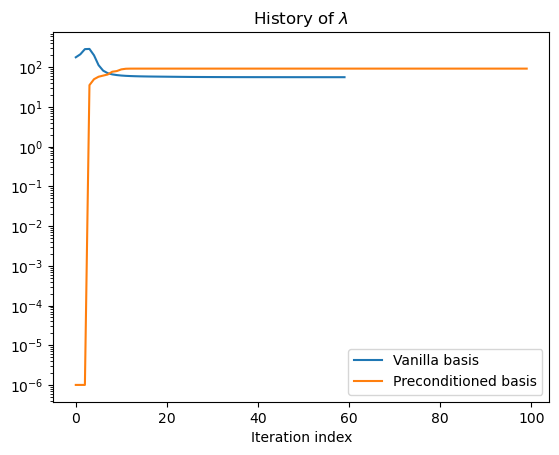

In [56]:
plt.semilogy(data["lambda_history"], label="Vanilla basis")
plt.semilogy(pdata["lambda_history"], label="Preconditioned basis")
plt.title("History of $\\lambda$")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

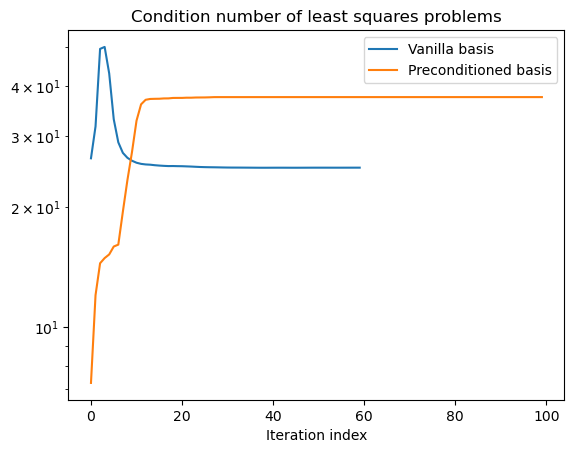

In [57]:
plt.semilogy(data["cond_ests"], label="Vanilla basis")
plt.semilogy(pdata["cond_ests"], label="Preconditioned basis")
plt.title("Condition number of least squares problems")
plt.xlabel("Iteration index")
plt.legend()
plt.show()

# VGKS

In [ ]:
vmmgks_solver = MMGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

vdata = iasgks_solver.solve(n_iter=60, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
                                    regparam=method, x_true=ground_truth, weight_params=weight_params,
                                    regparam_kwargs={"eta":1.01})

# pdata = iasgks_solver.solve_with_priorconditioning(n_iter=100, init_dim=5, x0=ground_truth, lambdah0=1e0, lambdah_max=1e7,
#                                                  regparam="dp", x_true=ground_truth, weight_params=weight_params,
#                                                  regparam_kwargs={"eta":1.01})